In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

cols = ['unit','cycle','settings1','settings2','settings3'] + [f's{i}' for i in range(1,22)]
train = pd.read_csv('../data/train_FD001.txt',sep = r'\s+', header = None, names= cols)
test = pd.read_csv('../data/test_FD001.txt',sep = r'\s+', header = None, names= cols)
rul_true = pd.read_csv('../data/RUL_FD001.txt',sep = r'\s+', header = None, names= ['RUL'])

print(train.shape, train['unit'].nunique())
train.head()

(20631, 26) 100


,unit,cycle,settings1,settings2,settings3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


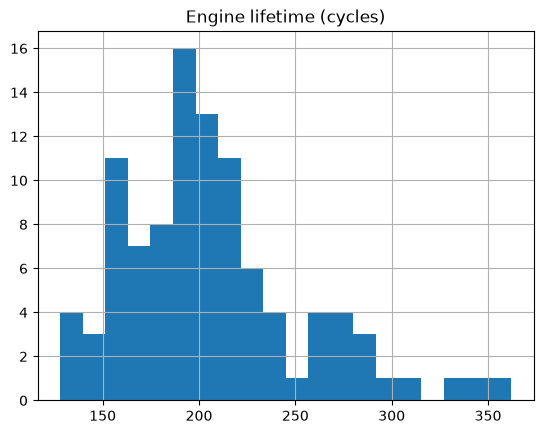

s1           0.000000e+00
settings3    0.000000e+00
s10          0.000000e+00
s18          0.000000e+00
s19          0.000000e+00
s16          3.469531e-18
s5           5.329200e-15
settings2    2.930621e-04
s6           1.388985e-03
settings1    2.187313e-03
s15          3.750504e-02
s8           7.098548e-02
s13          7.191892e-02
s21          1.082509e-01
s20          1.807464e-01
s11          2.670874e-01
s2           5.000533e-01
s12          7.375534e-01
s7           8.850923e-01
s17          1.548763e+00
s3           6.131150e+00
s4           9.000605e+00
s14          1.907618e+01
s9           2.208288e+01
unit         2.922763e+01
RUL          6.888099e+01
cycle        6.888099e+01
dtype: float64


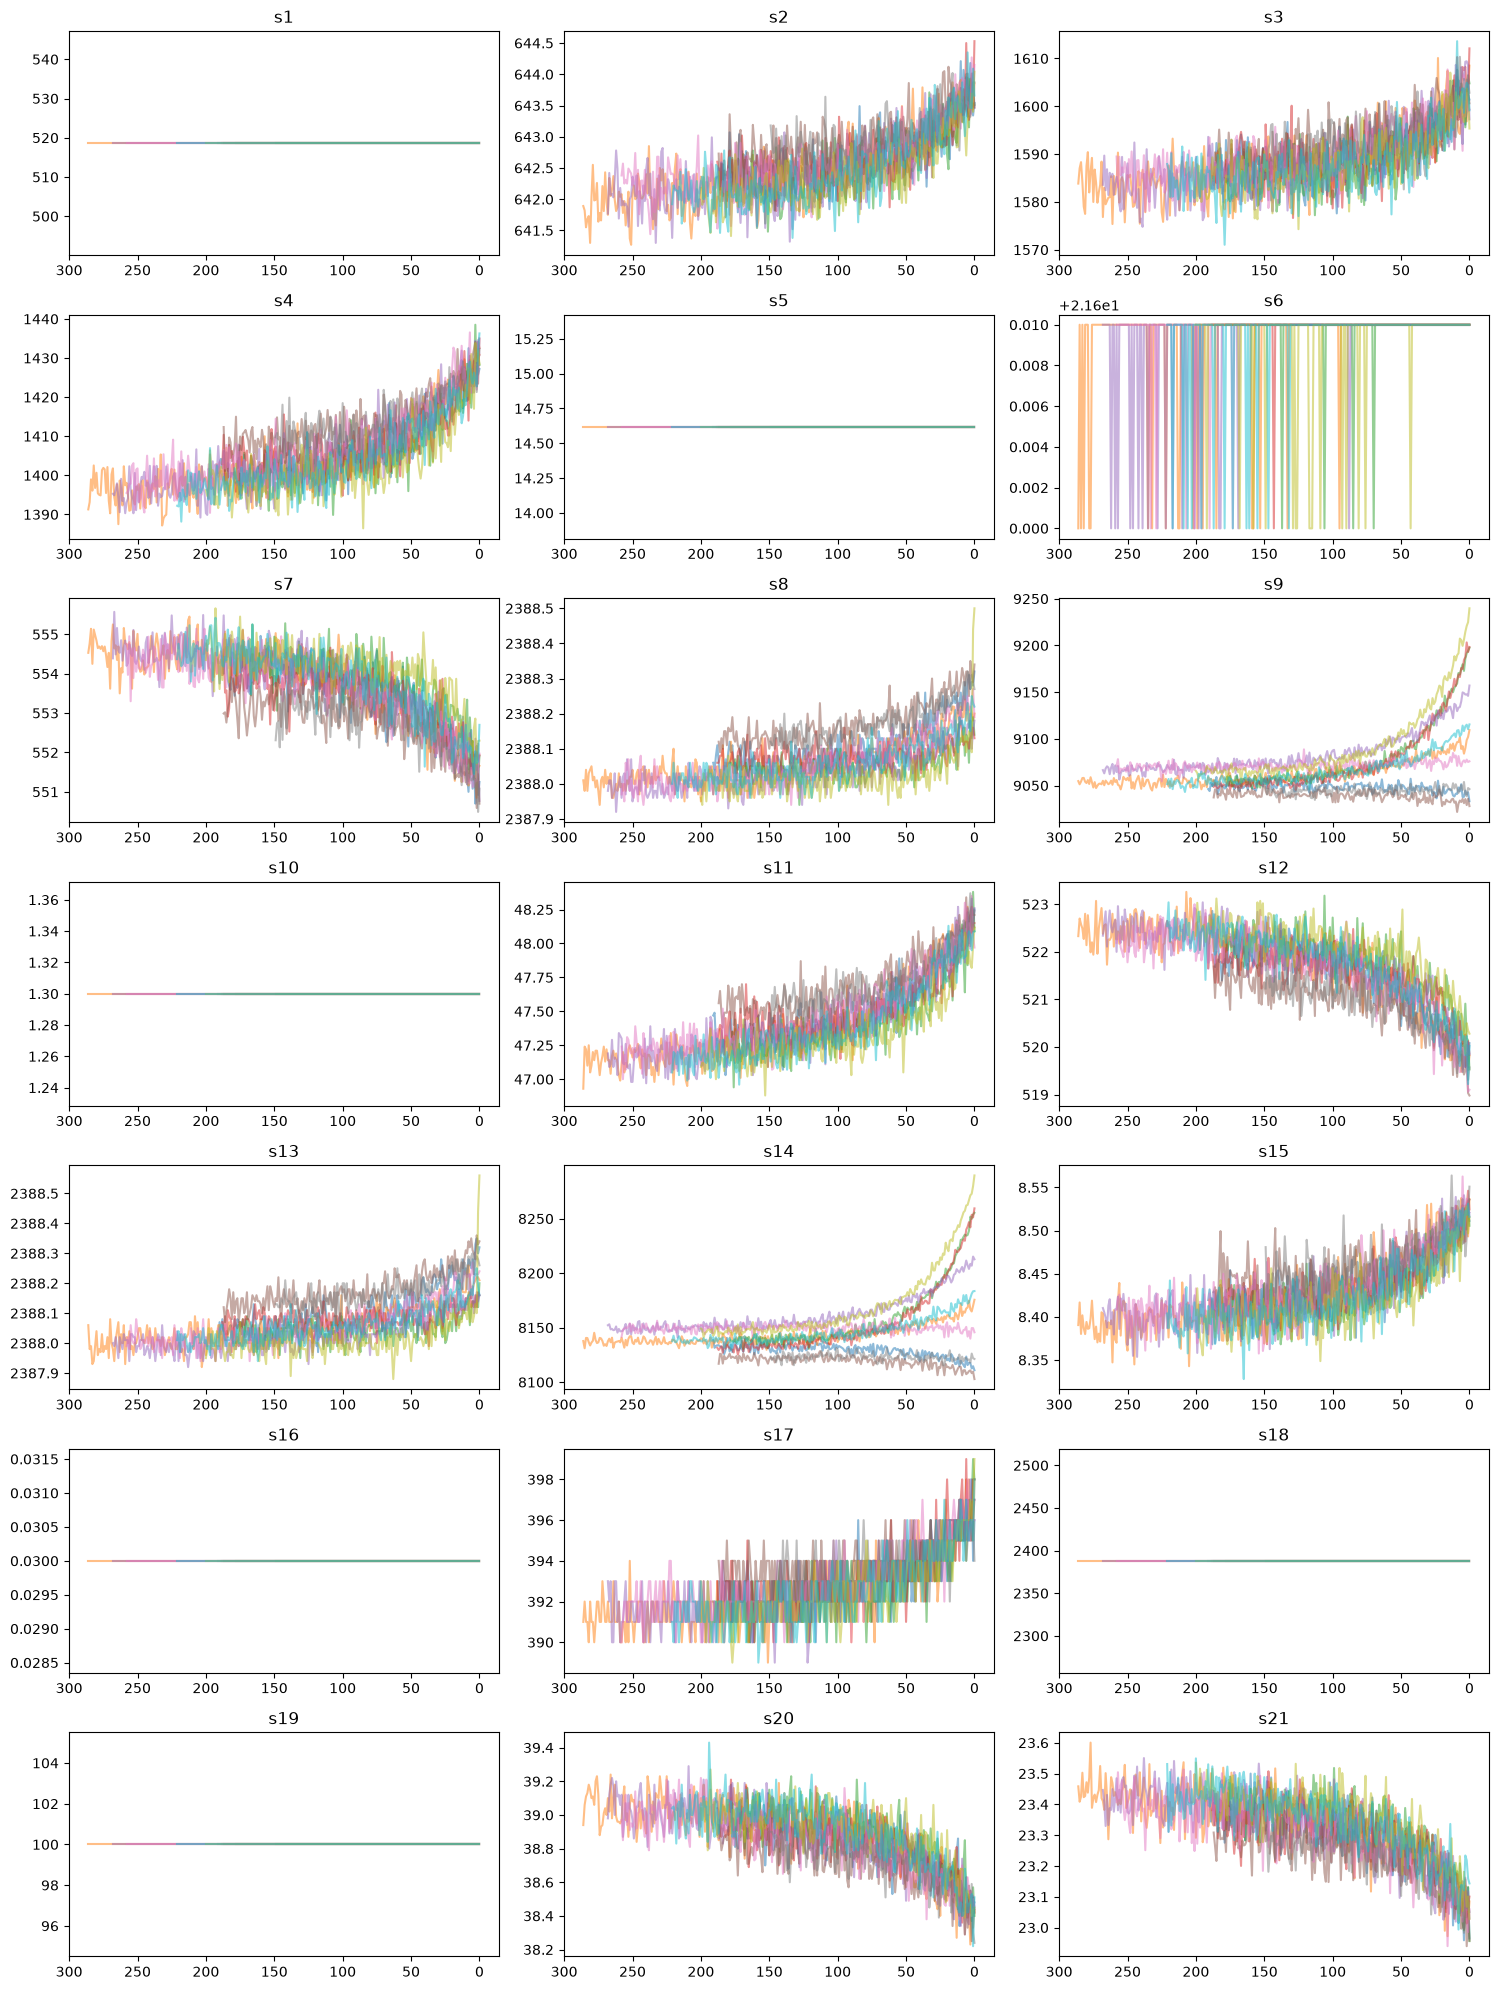

s11   -0.696228
s4    -0.678948
s15   -0.642667
s2    -0.606484
s17   -0.606154
s3    -0.584520
s8    -0.563968
s13   -0.562569
s9    -0.390102
s14   -0.306769
s6    -0.128348
s20    0.629428
s21    0.635662
s7     0.657223
s12    0.671983
RUL    1.000000
s1          NaN
s5          NaN
s10         NaN
s16         NaN
s18         NaN
s19         NaN
Name: RUL, dtype: float64


In [7]:
# how long do engines last?
life = train.groupby('unit')['cycle'].max()
print(life.describe())
life.hist(bins=20) 
plt.title('Engine lifetime (cycles)')
plt.show()

# creating the RUL label
train['RUL'] = train.groupby('unit')['cycle'].transform(max) - train['cycle']

# finding the useless(constant) columns
print(train.std().sort_values())

#how does each sensor change as the engine nears failure?
sensors = [f's{i}' for i in range(1,22)]
fig, axes = plt.subplots(7,3, figsize = (15,20))
for ax, s in zip(axes.flat, sensors):
    for u in train['unit'].unique()[:10]:
        d = train[train.unit == u]
        ax.plot(d['RUL'],d[s], alpha = 0.5)
    ax.set_title(s)
    ax.invert_xaxis()
plt.tight_layout()
plt.show()

# correlation with RUL
print(train[sensors +['RUL']].corr()['RUL'].sort_values())